### Superstore Sales (2015–2018)

**Setup and Imports**


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Make charts display properly and keep numbers readable
sns.set_theme(style="whitegrid")
pd.set_option('display.float_format', '{:,.2f}'.format)

**Load and Understand Data**

In [4]:
df = pd.read_csv('superstore_orders_raw.csv', dtype={'Postal Code': str})
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


In [5]:
print(df.shape)              

(9800, 18)


In [ ]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code          str
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object


In [7]:
print(df.isna().sum())       

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [9]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [10]:
df.describe()

,Row ID,Sales
count,"9,800.00","9,800.00"
mean,"4,900.50",230.77
std,"2,829.16",626.65
min,1.00,0.44
25%,"2,450.75",17.25
50%,"4,900.50",54.49
75%,"7,350.25",210.61
max,"9,800.00","22,638.48"


### Findings from Data Understanding

- The dataset has **9,800 rows** and **18 columns**.
- The **Postal Code** column has **11 missing values**. I will label these as "Unknown" during cleaning.
- There are **no duplicate rows**, so no records need to be removed.

**Clean the Data**

In [15]:
# Standardize column names
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(' ', '_', regex=False)
              .str.replace('-', '_', regex=False))

In [16]:
# Convert dates (day first)
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)
df['ship_date'] = pd.to_datetime(df['ship_date'], dayfirst=True)

In [17]:
# Fix Postal Codes
df['postal_code'] = df['postal_code'].str.zfill(5).fillna('Unknown')

In [ ]:
# Round Sales
df['sales'] = df['sales'].round(2)

In [19]:
# Check logic
print('Ship before order:', (df['ship_date'] < df['order_date']).sum())

Ship before order: 0


In [20]:
# Feature engineering
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['year_month'] = df['order_date'].dt.to_period('M').astype(str)
df['days_to_ship'] = (df['ship_date'] - df['order_date']).dt.days

Save the cleaned file, keeping the raw file unchanged

In [21]:
df.to_csv('superstore_clean.csv', index=False)

### EDA

**1. Monthly Sales Trend**

This line chart shows total sales for each month from 2015 to 2018, so we can see growth, seasonality, and sudden drops.

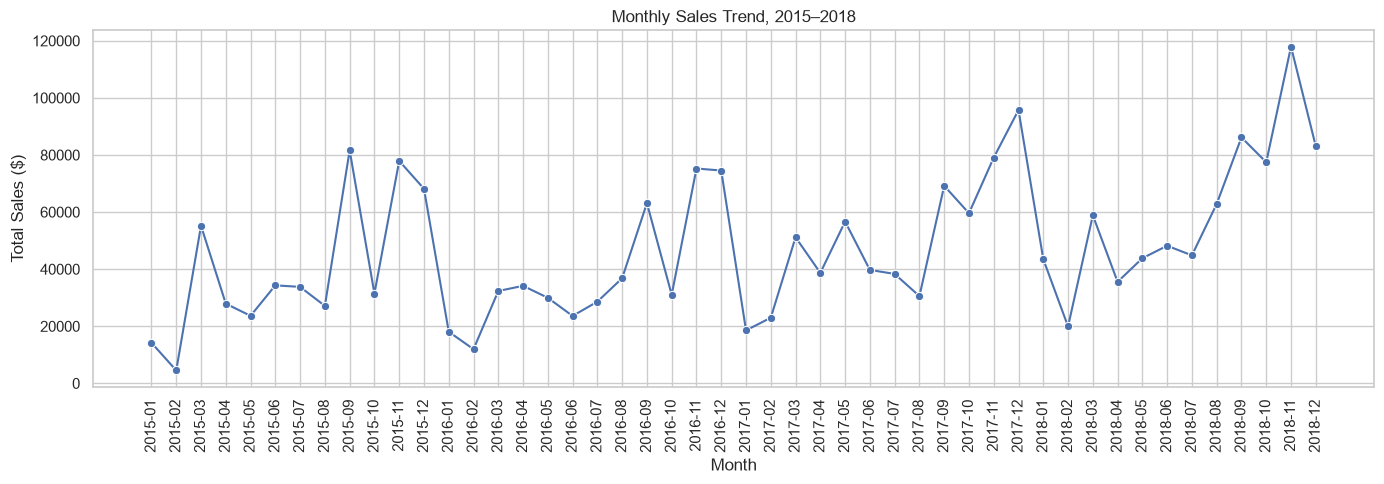

In [22]:
monthly = df.groupby('year_month', as_index=False)['sales'].sum()

plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly, x='year_month', y='sales', marker='o')
plt.xticks(rotation=90)
plt.title('Monthly Sales Trend, 2015–2018')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

**2. Sales by Region**

This bar chart compares total sales across the four regions.

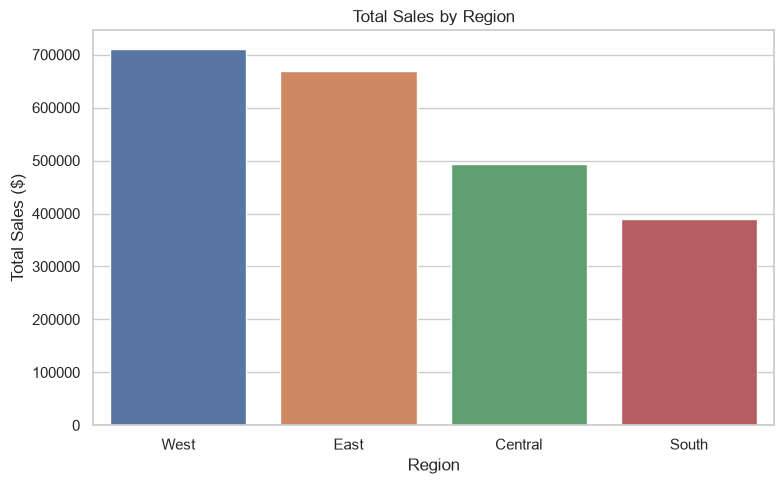

In [23]:
region_sales = (df.groupby('region', as_index=False)['sales'].sum()
                  .sort_values('sales', ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=region_sales, x='region', y='sales', hue='region', legend=False)
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

**3. Sales by Category**

This bar chart compares total sales across the three product categories.

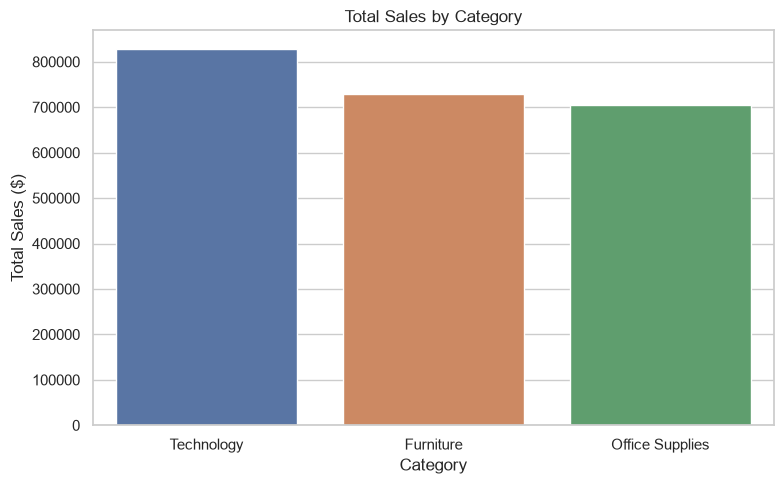

In [24]:
category_sales = (df.groupby('category', as_index=False)['sales'].sum()
                    .sort_values('sales', ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=category_sales, x='category', y='sales', hue='category', legend=False)
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

**4. Top 10 Sub-Categories by Sales**

 This horizontal bar chart ranks the ten highest-selling sub-categories and colors them by category.


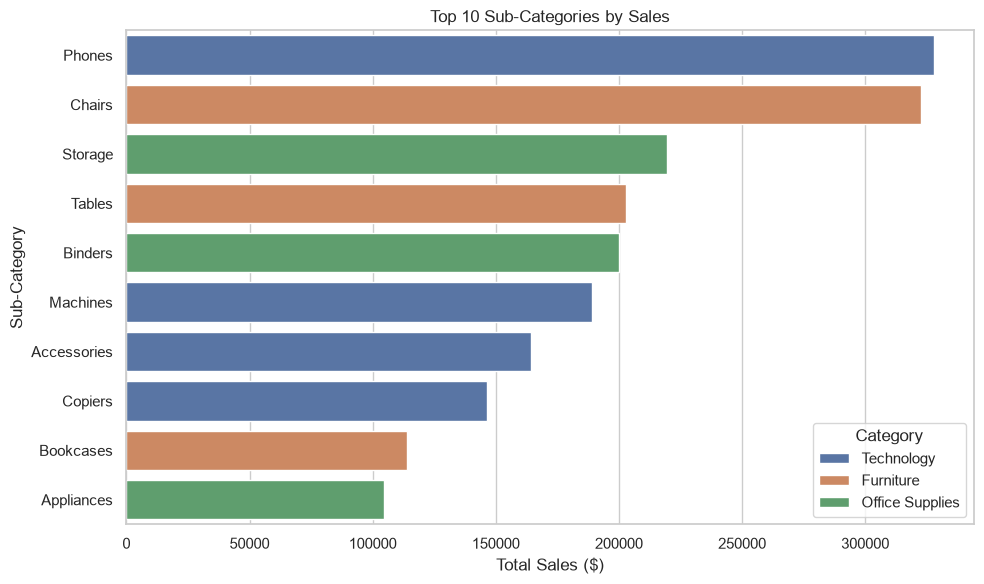

In [26]:
subcat_sales = (df.groupby(['category', 'sub_category'], as_index=False)['sales'].sum()
                  .sort_values('sales', ascending=False)
                  .head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=subcat_sales, x='sales', y='sub_category', hue='category', dodge=False)
plt.title('Top 10 Sub-Categories by Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Sub-Category')
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**5. Sales by Customer Segment**

This bar chart compares total sales across the three customer segments: Consumer, Corporate, and Home Office.

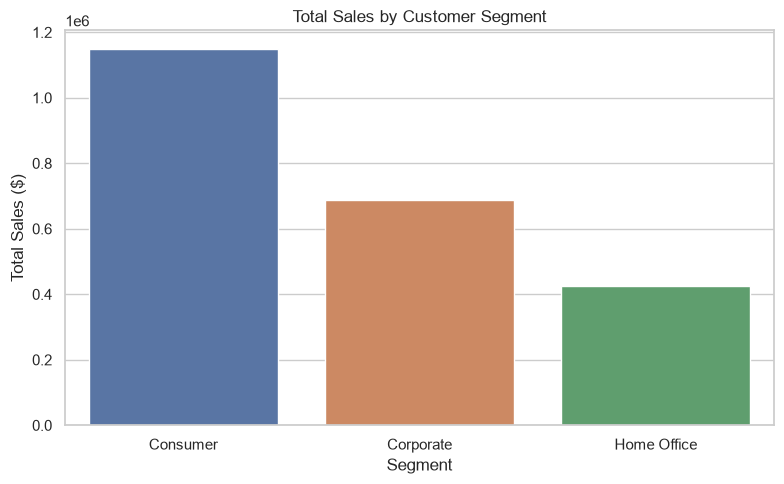

In [27]:
segment_sales = (df.groupby('segment', as_index=False)['sales'].sum()
                   .sort_values('sales', ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=segment_sales, x='segment', y='sales', hue='segment', legend=False)
plt.title('Total Sales by Customer Segment')
plt.xlabel('Segment')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

**6. Shipping Days by Ship Mode**

This box plot shows the typical shipping time and the spread of shipping days for each ship mode. The line in the middle of each box is the median, and the dots outside the box are unusual orders.


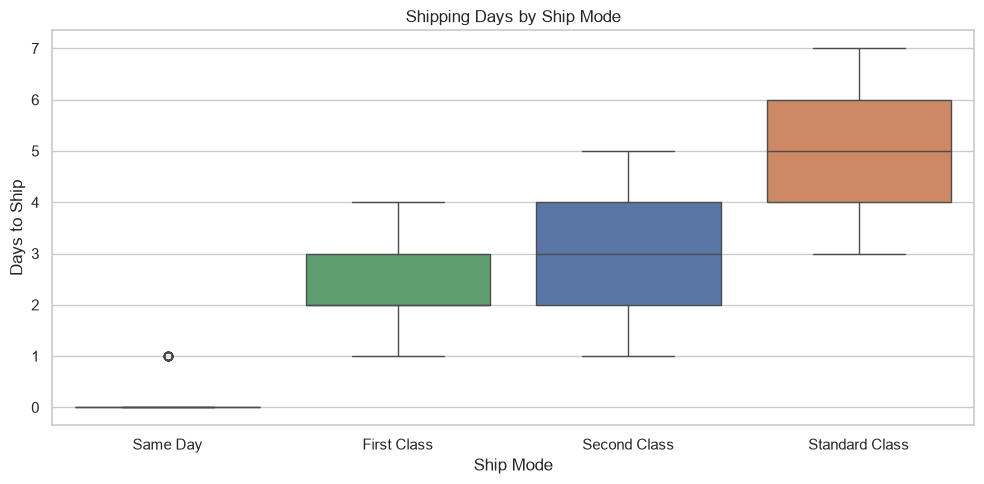

In [28]:
ship_order = (df.groupby('ship_mode')['days_to_ship'].median()
                .sort_values().index)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='ship_mode', y='days_to_ship', order=ship_order, hue='ship_mode', legend=False)
plt.title('Shipping Days by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Days to Ship')
plt.tight_layout()
plt.show()

## Key Findings

**Overview:** The dataset contains 4,922 orders, 793 customers, and total sales of $2,261,536.78, with an average order value of $459.48.

1. **Sales grew strongly from 2015 to 2018.** Yearly sales rose from $479,856.21 in 2015 to $722,052.02 in 2018, an increase of 50.47%. Sales dipped 4.26% in 2016 before growing 30.64% in 2017 and 20.30% in 2018. The growth suggests the business expanded its order volume over time.

2. **The West and East regions generate most of the sales.** West contributed $710,219.68 (31.40%) and East contributed $669,518.73 (29.60%), together 61.00% of total sales. South is the smallest region at $389,151.46 (17.21%), so it has the most room for growth.

3. **Technology is the top category despite having fewer orders.** Technology generated $827,455.87 (36.59%), ahead of Furniture at $728,658.58 (32.22%) and Office Supplies at $705,422.33 (31.19%). Office Supplies has the most rows (5,909 of 9,800), but its sales per row are the lowest, which means its items have smaller prices.

4. **Two sub-categories drive a large share of sales.** Phones ($327,782.45, 14.49%) and Chairs ($322,822.73, 14.27%) together make up 28.76% of total sales. The top 10 sub-categories make up 88.03% of total sales.

5. **Consumers are the largest customer segment.** The Consumer segment generated $1,148,060.53 (50.76%), followed by Corporate at $688,494.07 (30.44%) and Home Office at $424,982.18 (18.79%).

6. **Sales are shifting between sub-categories.** From 2017 to 2018, Appliances rose 54.6%, Art rose 49.8%, and Binders rose 46.4%. In contrast, Envelopes fell 24.2% and Machines fell 22.1%, dropping from $55,906.89 to $43,544.68.

7. **Standard Class shipping carries most of the sales but is the slowest.** Standard Class accounts for 59.29% of sales and takes an average of 5.01 days to ship, compared with 2.18 days for First Class.

8. **Customer loyalty is high, and the customer base is spread out.** 98.36% of customers placed more than one order. The top 10 customers account for only 6.80% of sales, so the business does not depend on a few buyers. The largest single customer is SM-20320, with $25,043.05.

##  Recommendations

1. **Protect and grow the Phones and Chairs sub-categories.** Together they make up 28.76% of sales. Make sure stock and pricing for these products stay strong, since a problem with either would affect a large share of revenue.

2. **Investigate the decline in Machines and Envelopes.** Machines fell 22.1% and Envelopes fell 24.2% from 2017 to 2018. Review whether the cause is competition, pricing, or lower demand, and decide whether to revive or reduce these lines.

3. **Build sales in the South region.** South has the lowest sales at $389,151.46 (17.21%). Review sales coverage and customer reach there, and compare its performance with the West and East regions to find the gap.